# Aviation Accidents Analysis

You are part of a consulting firm that is tasked to do an analysis of commercial and passenger jet airline safety. The client (an airline/airplane insurer) is interested in knowing what types of aircraft (makes/models) exhibit low rates of total destruction and low likelihood of fatal or serious passenger injuries in the event of an accident. They are also interested in any general variables/conditions that might be at play. Your analysis will be based off of aviation accident data accumulated from the years 1948-2023. 

Our client is only interested in airplane makes/models that are professional builds and could potentially still be active. Assume a max lifetime of 40 years for a make/model retirement and make sure to filter your data accordingly (i.e. from 1983 onwards). They would also like separate recommendations for small aircraft vs. larger passenger models. **In addition, make sure that claims that you make are statistically robust and that you have enough samples when making comparisons between groups.**


In this summative assessment you will demonstrate your ability to:
- Use Pandas to load, inspect, and clean the dataset appropriately. 
- Transform relevant columns to create measures that address the problem at hand.
- **conduct EDA: visualization and statistical measures to understand the structure of the data**
- **recommend a set of manufacturers to consider as well as specific airplanes conforming to the client's request**
- **discuss the relationship between serious injuries/airplane damage incurred and at least *two* factors at play in the incident. You must provide supporting evidence (visuals, summary statistics, tables) for each claim you make.**

In [1]:
# loading relevant packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Exploratory Data Analysis  
- Load in the cleaned data

In [2]:
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid", context="notebook")

df = pd.read_csv("data/AviationData_cleaned.csv", parse_dates=["Event.Date"], low_memory=False)
df["Any.Fatal.Serious"] = (df["Total.Fatal.Serious"] > 0).astype(int)   # 1 if at least one occupant was fatally/seriously injured
print(f"Rows: {df.shape[0]:,}   Columns: {df.shape[1]}")
print(f"Plane types (Make.Model): {df['Make.Model'].nunique():,}   Makes: {df['Make'].nunique()}")
df.head(3)

Rows: 57,468   Columns: 35
Plane types (Make.Model): 2,464   Makes: 49


,Event.Id,Investigation.Type,Accident.Number,Event.Date,Location,Country,Latitude,Longitude,Airport.Code,Airport.Name,Injury.Severity,Aircraft.Damage,Aircraft.Category,Registration.Number,Make,Model,Amateur.Built,Number.of.Engines,Engine.Type,Purpose.of.flight,Total.Fatal.Injuries,Total.Serious.Injuries,Total.Minor.Injuries,Total.Uninjured,Weather.Condition,Broad.phase.of.flight,Report.Status,Publication.Date,Total.Passengers,Total.Fatal.Serious,Fatal.Serious.Fraction,Destroyed,Make.Model,Event.Year,Any.Fatal.Serious
0,20001214X42095,Accident,SEA83LA036,1983-01-01,"NEWPORT, OR",United States,NaN,NaN,ONP,NEWPORT MUNICIPAL,Non-Fatal,Substantial,Airplane,N1296M,CESSNA,182P,No,1.0,Reciprocating,Personal,0.0,0.0,1.0,3.0,VMC,Approach,Probable Cause,NaN,4.0,0.0,0.0,0.0,CESSNA 182P,1983,0
1,20001214X42067,Accident,MKC83LA056,1983-01-01,"WOODBINE, IA",United States,NaN,NaN,3YR,MUNICIPAL,Non-Fatal,Substantial,Airplane,N2639C,CESSNA,182RG,No,1.0,Reciprocating,Personal,0.0,0.0,0.0,2.0,VMC,Landing,Probable Cause,NaN,2.0,0.0,0.0,0.0,CESSNA 182RG,1983,0
2,20001214X42063,Accident,MKC83LA050,1983-01-01,"MARYVILLE, MO",United States,NaN,NaN,78Y,RANKIN,Non-Fatal,Substantial,Airplane,N58664,CESSNA,182P,No,1.0,Reciprocating,Personal,0.0,0.0,0.0,1.0,VMC,Takeoff,Probable Cause,NaN,1.0,0.0,0.0,0.0,CESSNA 182P,1983,0


**First look at the structure of the data**

Each row is one aircraft in one event. The two key outcome measures built in the cleaning notebook are:
- `Fatal.Serious.Fraction` - fraction of the occupants who were fatally or seriously injured (0 to 1)
- `Destroyed` - 1 if the aircraft was destroyed, 0 otherwise (NaN if unknown)

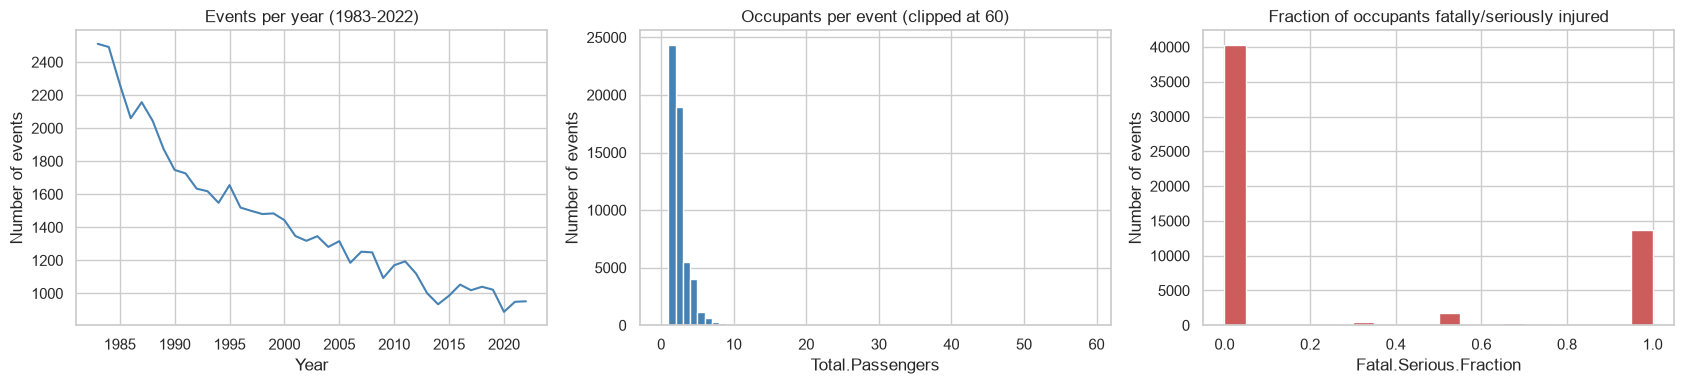

       Total.Passengers  Fatal.Serious.Fraction  Destroyed
count         57468.000               57468.000  55933.000
mean              6.524                   0.266      0.206
std              29.068                   0.426      0.404
min               1.000                   0.000      0.000
25%               1.000                   0.000      0.000
50%               2.000                   0.000      0.000
75%               2.000                   0.500      0.000
max             588.000                   1.000      1.000


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))

# events per year
df["Event.Year"].value_counts().sort_index().plot(ax=axes[0], color="steelblue")
axes[0].set(title="Events per year (1983-2022)", xlabel="Year", ylabel="Number of events")

# occupants per event (the long right tail is clipped at 60 for readability)
axes[1].hist(df["Total.Passengers"], bins=np.arange(0, 60, 1), color="steelblue")
axes[1].set(title="Occupants per event (clipped at 60)", xlabel="Total.Passengers", ylabel="Number of events")

# outcome distribution
axes[2].hist(df["Fatal.Serious.Fraction"], bins=20, color="indianred")
axes[2].set(title="Fraction of occupants fatally/seriously injured", xlabel="Fatal.Serious.Fraction", ylabel="Number of events")
plt.tight_layout(); plt.show()

print(df[["Total.Passengers", "Fatal.Serious.Fraction", "Destroyed"]].describe().round(3))

The outcome is strongly **bimodal**: most events involve no serious/fatal injury (fraction 0), and a second cluster sits at 1 (everyone on board seriously or fatally injured). A mean of this fraction is therefore best read as "the average share of occupants badly hurt when an event happens", and the *distribution* (violin / strip plots) matters as much as the mean. Most events involve only 1-2 occupants, i.e. small aircraft.

## Explore safety metrics across models/makes
- Remember that the client is interested in separate recommendations for smaller airplanes and larger airplanes. Choose a passenger threshold of 20 and separate the plane types. 

**How do we decide whether a plane *type* is small or large?**

The size class has to be a property of the **plane type** (`Make.Model`), not of a single event: a Boeing 737 that crashed on a positioning flight with a crew of three is still a large aircraft. We use the **90th percentile of occupants across all events of that type** and compare it with the threshold of 20.

We use the 90th percentile and not the maximum because the maximum is unreliable: a single data-entry error or a collision record can make a Cessna 172 look like a 124-seat aircraft. The table below shows why.

In [4]:
PASSENGER_THRESHOLD = 20

occ = df.groupby("Make.Model")["Total.Passengers"]
type_size = pd.DataFrame({"events": occ.size(), "median": occ.median(),
                          "p90": occ.quantile(0.9), "max": occ.max()})

examples = ["CESSNA 172M", "CESSNA 421C", "BEECH 1900C", "BOEING 737", "BOEING 747", "AIRBUS A320"]
type_size.loc[[e for e in examples if e in type_size.index]]

,events,median,p90,max
Make.Model,,,,
CESSNA 172M,758,2.0,4.0,124.0
CESSNA 421C,123,4.0,6.8,208.0
BEECH 1900C,37,8.0,20.4,22.0
BOEING 737,248,121.5,181.3,406.0
BOEING 747,46,4.0,376.5,588.0
AIRBUS A320,35,137.0,184.6,359.0


In [5]:
df["Size.Class"] = np.where(df["Make.Model"].map(type_size["p90"]) >= PASSENGER_THRESHOLD, "Large", "Small")

summary = df.groupby("Size.Class").agg(
    events=("Make.Model", "size"),
    plane_types=("Make.Model", "nunique"),
    makes=("Make", "nunique"),
    mean_occupants=("Total.Passengers", "mean"),
    mean_fatal_serious_fraction=("Fatal.Serious.Fraction", "mean"),
    destroyed_rate=("Destroyed", "mean"),
    incident_share=("Investigation.Type", lambda s: (s == "Incident").mean())).round(3)
summary

,events,plane_types,makes,mean_occupants,mean_fatal_serious_fraction,destroyed_rate,incident_share
Size.Class,,,,,,,
Large,2194,353,12,118.419,0.073,0.124,0.457
Small,55274,2111,49,2.083,0.274,0.208,0.015


Large aircraft account for only ~4% of events but they are a very different population: far fewer events end in serious/fatal injury, but those that do involve many more people. Note also that **~46% of the large-aircraft events are NTSB "Incidents"** (minor events such as turbulence injuries) versus 1.5% for small aircraft, which dilutes their averages. We keep them (the lab asks to keep all events) but check the conclusions on accidents only below. This difference is exactly why the client wants separate recommendations.

Two helper functions are defined next: one summarises any grouping (sample size, mean injury fraction with a 95% confidence interval, destroyed rate with a Wilson 95% interval, which behaves well for proportions near 0), and the other applies a minimum-sample filter, so that no group is compared on too few events.

In [6]:
def wilson_interval(k, n, z=1.96):
    """95% Wilson score interval for a proportion k/n (robust for small n and p near 0)."""
    n = np.asarray(n, dtype=float); k = np.asarray(k, dtype=float)
    p = np.divide(k, n, out=np.zeros_like(n), where=n > 0)
    denom = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return centre - half, centre + half

def hbar(ax, tbl, val, err, color, n_col="n", xlabel=""):
    """Horizontal bars with the sample size in the tick label; err may be a half-width or a 2xN array."""
    y = np.arange(len(tbl))
    ax.barh(y, tbl[val], xerr=err, color=color, alpha=0.85, error_kw=dict(ecolor="black", capsize=3, lw=1))
    ax.set_yticks(y); ax.set_yticklabels([f"{m}  (n={int(n):,})" for m, n in zip(tbl.index, tbl[n_col])])
    ax.invert_yaxis(); ax.set_xlim(left=0); ax.set_xlabel(xlabel); ax.set_ylabel("")

def summarize(data, by):
    """Safety summary for each group in column `by`."""
    g = data.groupby(by)
    out = g.agg(n=("Fatal.Serious.Fraction", "size"),
                mean_fs=("Fatal.Serious.Fraction", "mean"),
                sd_fs=("Fatal.Serious.Fraction", "std"),
                n_damage=("Destroyed", "count"),          # events with a known damage level
                destroyed_rate=("Destroyed", "mean"),
                any_fs=("Any.Fatal.Serious", "mean"),      # share of events with >= 1 fatal/serious injury
                k_any=("Any.Fatal.Serious", "sum"))
    out["ci_fs"] = 1.96 * out["sd_fs"] / np.sqrt(out["n"])           # normal-approx 95% CI half-width
    k = (out["destroyed_rate"] * out["n_damage"]).round()
    out["destroyed_lo"], out["destroyed_hi"] = wilson_interval(k, out["n_damage"])
    # Wilson interval for the share of events with a serious/fatal injury. Unlike the interval on the mean fraction,
    # it does NOT collapse to zero width when every observed event happened to be injury-free.
    out["any_fs_lo"], out["any_fs_hi"] = wilson_interval(out["k_any"], out["n"])
    return out

small = df[df["Size.Class"] == "Small"]
large = df[df["Size.Class"] == "Large"]
print(f"Small aircraft events: {len(small):,}   Large aircraft events: {len(large):,}")

Small aircraft events: 55,274   Large aircraft events: 2,194


#### Analyzing Makes

Explore the human injury risk profile for small and larger Makes:
- choose the 15 makes for each group possessing the lowest mean fatal/seriously injured fraction
- plot the mean fatal/seriously injured fraction for each of these subgroups side-by-side

In [7]:
MIN_MAKE_EVENTS = 30        # minimum events (within the size group) for a make to be compared

make_small = summarize(small, "Make"); make_small = make_small[make_small["n"] >= MIN_MAKE_EVENTS]
make_large = summarize(large, "Make"); make_large = make_large[make_large["n"] >= MIN_MAKE_EVENTS]
print(f"Makes with >= {MIN_MAKE_EVENTS} events:  small group = {len(make_small)},  large group = {len(make_large)}")

top_small = make_small.sort_values(["mean_fs", "n"], ascending=[True, False]).head(15)
top_large = make_large.sort_values(["mean_fs", "n"], ascending=[True, False]).head(15)

cols = ["n", "mean_fs", "ci_fs", "destroyed_rate"]
print("\nSMALL aircraft - 15 makes with the lowest mean fatal/serious fraction")
display(top_small[cols].round(3))
print("LARGE aircraft - makes with the lowest mean fatal/serious fraction (all that meet the sample threshold)")
display(top_large[cols].round(3))

Makes with >= 30 events:  small group = 45,  large group = 9

SMALL aircraft - 15 makes with the lowest mean fatal/serious fraction


C:\Users\ADMIN\AppData\Local\Temp\ipykernel_11208\3737016603.py:5: RuntimeWarning: divide by zero encountered in divide
  denom = 1 + z**2 / n
C:\Users\ADMIN\AppData\Local\Temp\ipykernel_11208\3737016603.py:6: RuntimeWarning: divide by zero encountered in divide
  centre = (p + z**2 / (2 * n)) / denom
C:\Users\ADMIN\AppData\Local\Temp\ipykernel_11208\3737016603.py:6: RuntimeWarning: invalid value encountered in divide
  centre = (p + z**2 / (2 * n)) / denom
C:\Users\ADMIN\AppData\Local\Temp\ipykernel_11208\3737016603.py:7: RuntimeWarning: invalid value encountered in divide
  half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
C:\Users\ADMIN\AppData\Local\Temp\ipykernel_11208\3737016603.py:7: RuntimeWarning: divide by zero encountered in divide
  half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom


,n,mean_fs,ci_fs,destroyed_rate
Make,,,,
WACO,99,0.130,0.064,0.102
GREAT LAKES,53,0.142,0.093,0.113
SCHWEIZER,120,0.150,0.064,0.225
MAULE,495,0.162,0.031,0.093
SWEARINGEN,93,0.163,0.073,0.151
BOEING,366,0.173,0.036,0.125
GRUMMAN,1154,0.177,0.022,0.218
HELIO,70,0.178,0.086,0.159
AVIAT,223,0.200,0.050,0.063


LARGE aircraft - makes with the lowest mean fatal/serious fraction (all that meet the sample threshold)


,n,mean_fs,ci_fs,destroyed_rate
Make,,,,
MCDONNELL DOUGLAS,304,0.035,0.017,0.086
LOCKHEED,34,0.043,0.059,0.130
BOMBARDIER,103,0.047,0.035,0.056
EMBRAER,124,0.057,0.035,0.061
BOEING,1266,0.067,0.013,0.116
AIRBUS,199,0.084,0.036,0.170
DE HAVILLAND,54,0.157,0.088,0.250
DOUGLAS,64,0.177,0.090,0.212
BEECH,37,0.326,0.153,0.303


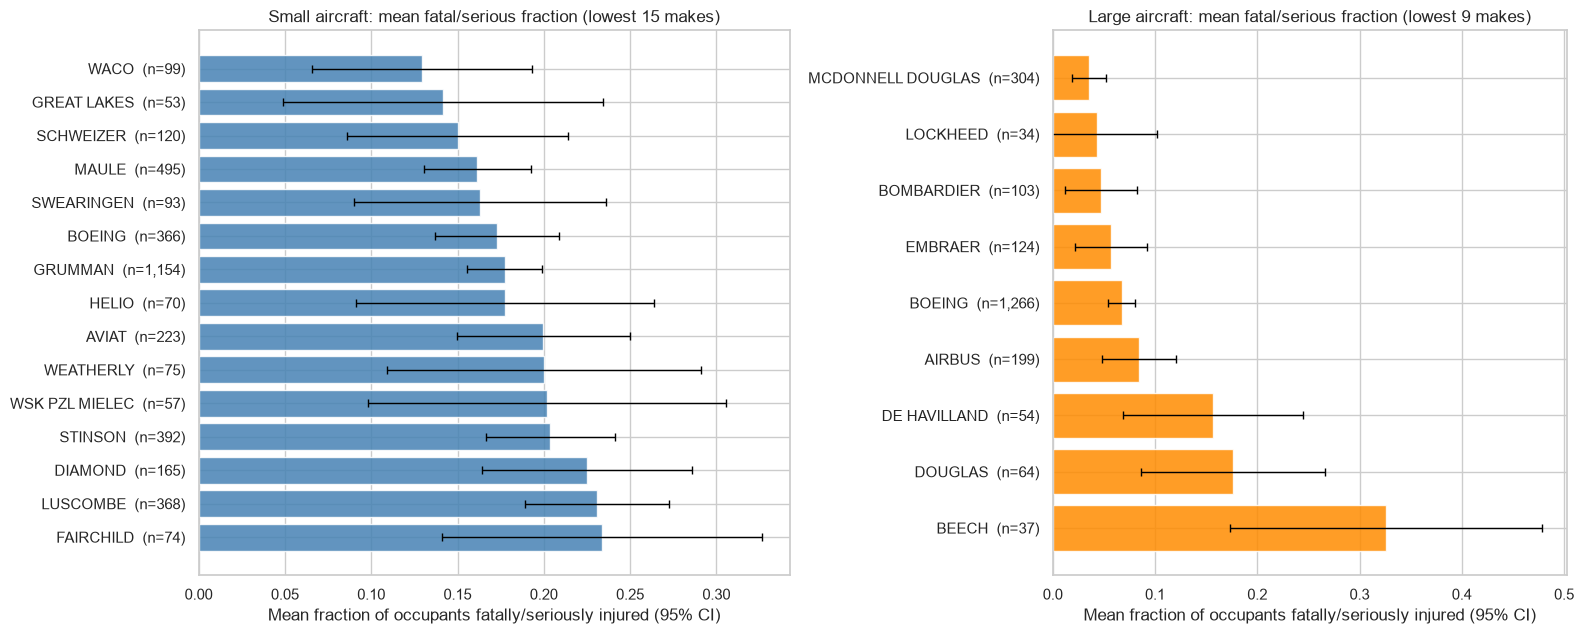

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5), gridspec_kw={"width_ratios": [1.15, 1]})
for ax, tbl, title, color in [(axes[0], top_small, "Small aircraft", "steelblue"),
                              (axes[1], top_large, "Large aircraft", "darkorange")]:
    hbar(ax, tbl, "mean_fs", tbl["ci_fs"], color, xlabel="Mean fraction of occupants fatally/seriously injured (95% CI)")
    ax.set_title(f"{title}: mean fatal/serious fraction (lowest {len(tbl)} makes)")
plt.tight_layout(); plt.show()

**Distribution of injury rates: small makes**

Use a violinplot to look at the distribution of the fraction of passengers serious/fatally injured for small airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

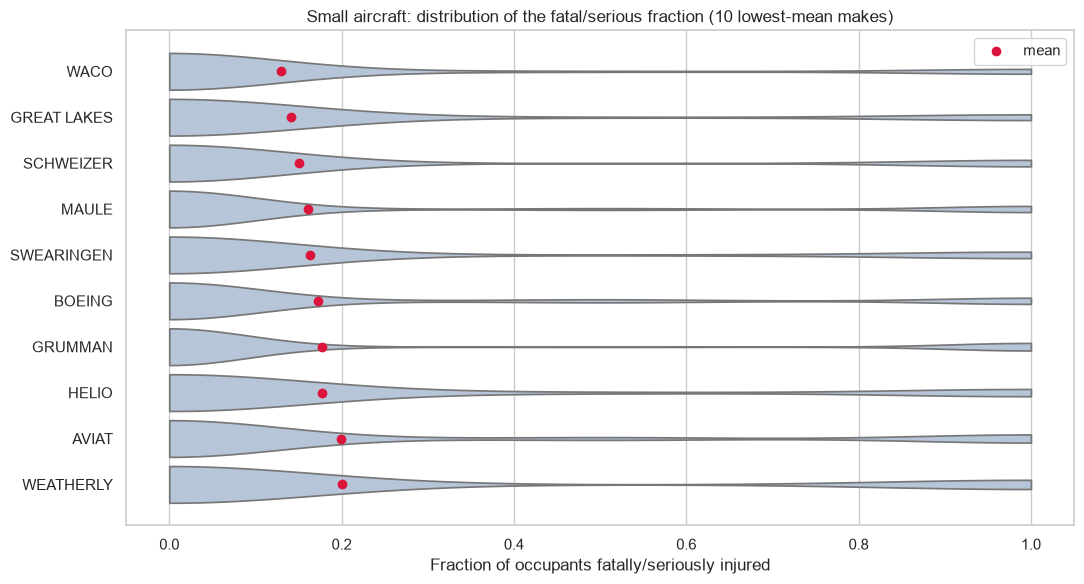

In [9]:
order_small10 = top_small.index[:10].tolist()

plt.figure(figsize=(11, 6))
sns.violinplot(data=small[small["Make"].isin(order_small10)], y="Make", x="Fatal.Serious.Fraction",
               order=order_small10, orient="h", cut=0, inner=None, density_norm="width", color="lightsteelblue")
plt.scatter(top_small.loc[order_small10, "mean_fs"], range(10), color="crimson", zorder=5, label="mean")
plt.title("Small aircraft: distribution of the fatal/serious fraction (10 lowest-mean makes)")
plt.xlabel("Fraction of occupants fatally/seriously injured"); plt.ylabel(""); plt.legend()
plt.tight_layout(); plt.show()

**Distribution of injury rates: large makes**

Use a stripplot to look at the distribution of the fraction of passengers serious/fatally injured for large airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

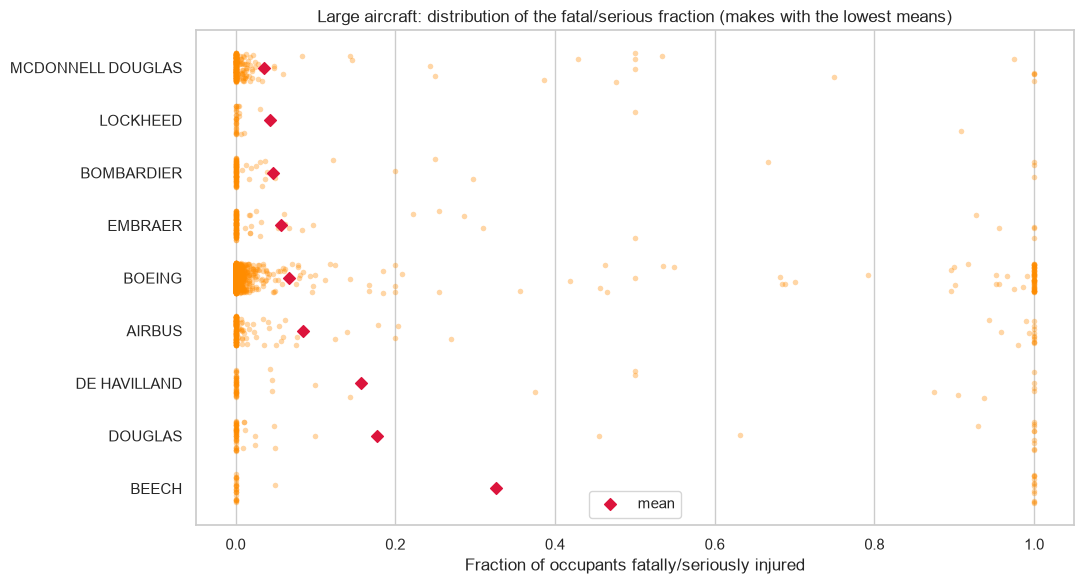

In [10]:
order_large10 = top_large.index[:10].tolist()

plt.figure(figsize=(11, 6))
sns.stripplot(data=large[large["Make"].isin(order_large10)], y="Make", x="Fatal.Serious.Fraction",
              order=order_large10, orient="h", jitter=0.28, alpha=0.35, size=4, color="darkorange")
plt.scatter(top_large.loc[order_large10, "mean_fs"], range(len(order_large10)), color="crimson", zorder=5, marker="D", label="mean")
plt.title("Large aircraft: distribution of the fatal/serious fraction (makes with the lowest means)")
plt.xlabel("Fraction of occupants fatally/seriously injured"); plt.ylabel(""); plt.legend()
plt.tight_layout(); plt.show()

**Evaluate the rate of aircraft destruction for both small and large aircraft by Make.** 

Sort your results and keep the lowest 15.

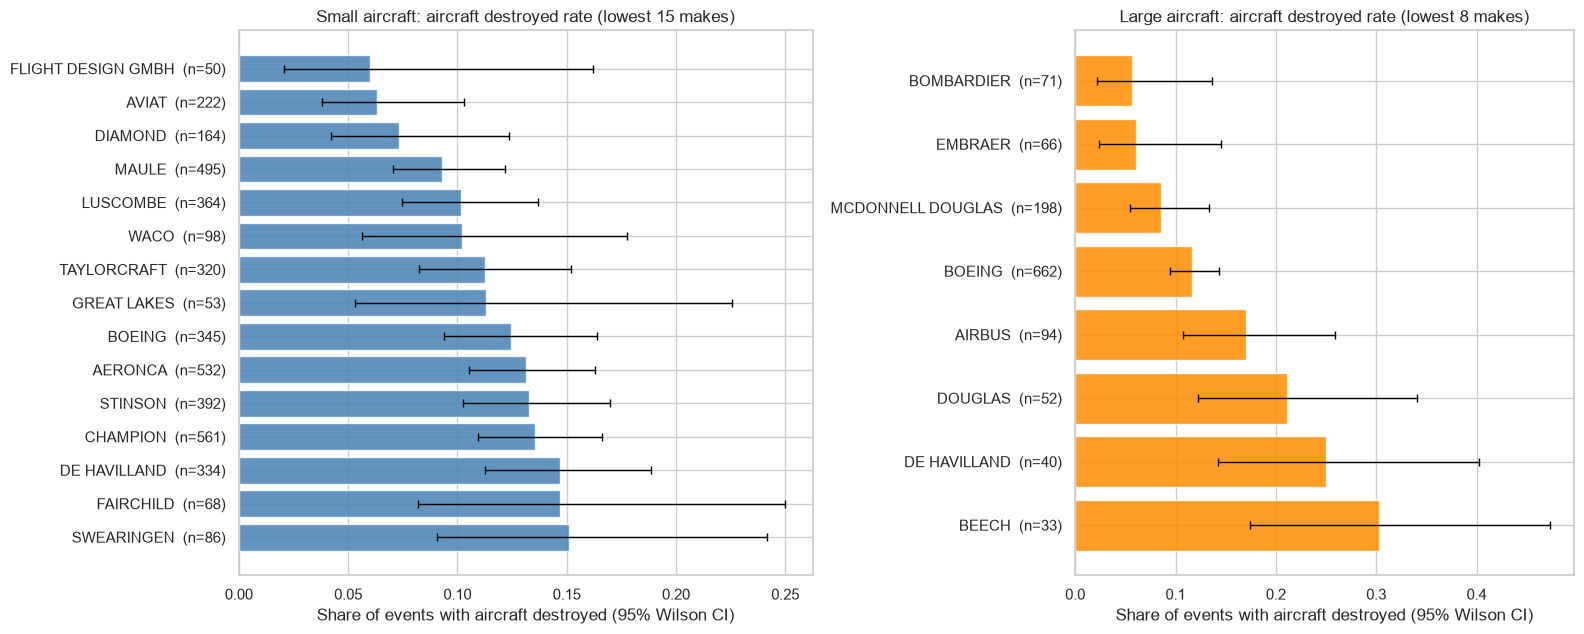

SMALL


,n_damage,destroyed_rate,destroyed_lo,destroyed_hi
Make,,,,
FLIGHT DESIGN GMBH,50,0.060,0.021,0.162
AVIAT,222,0.063,0.038,0.103
DIAMOND,164,0.073,0.042,0.124
MAULE,495,0.093,0.070,0.122
LUSCOMBE,364,0.102,0.075,0.137
WACO,98,0.102,0.056,0.178
TAYLORCRAFT,320,0.112,0.082,0.152
GREAT LAKES,53,0.113,0.053,0.226
BOEING,345,0.125,0.094,0.164


LARGE


,n_damage,destroyed_rate,destroyed_lo,destroyed_hi
Make,,,,
BOMBARDIER,71,0.056,0.022,0.136
EMBRAER,66,0.061,0.024,0.146
MCDONNELL DOUGLAS,198,0.086,0.054,0.133
BOEING,662,0.116,0.094,0.143
AIRBUS,94,0.170,0.108,0.259
DOUGLAS,52,0.212,0.122,0.340
DE HAVILLAND,40,0.250,0.142,0.402
BEECH,33,0.303,0.174,0.473


In [11]:
MIN_DAMAGE_N = 30      # events with a known damage level

dest_small = make_small[make_small["n_damage"] >= MIN_DAMAGE_N].sort_values(["destroyed_rate", "n"], ascending=[True, False]).head(15)
dest_large = make_large[make_large["n_damage"] >= MIN_DAMAGE_N].sort_values(["destroyed_rate", "n"], ascending=[True, False]).head(15)

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5), gridspec_kw={"width_ratios": [1.15, 1]})
for ax, tbl, title, color in [(axes[0], dest_small, "Small aircraft", "steelblue"),
                              (axes[1], dest_large, "Large aircraft", "darkorange")]:
    err = np.vstack([tbl["destroyed_rate"] - tbl["destroyed_lo"], tbl["destroyed_hi"] - tbl["destroyed_rate"]])
    hbar(ax, tbl, "destroyed_rate", err, color, n_col="n_damage", xlabel="Share of events with aircraft destroyed (95% Wilson CI)")
    ax.set_title(f"{title}: aircraft destroyed rate (lowest {len(tbl)} makes)")
plt.tight_layout(); plt.show()

print("SMALL"); display(dest_small[["n_damage", "destroyed_rate", "destroyed_lo", "destroyed_hi"]].round(3))
print("LARGE"); display(dest_large[["n_damage", "destroyed_rate", "destroyed_lo", "destroyed_hi"]].round(3))

#### Provide a short discussion on your findings for your summary statistics and plots:
- Make any recommendations for Makes here based off of the destroyed fraction and fraction fatally/seriously injured
- Comment on the calculated statistics and any corresponding distributions you have visualized.

In [12]:
def combined(tbl):
    """Rank each make on both metrics (1 = best) and average the ranks."""
    t = tbl[tbl["n_damage"] >= MIN_DAMAGE_N].copy()
    t["rank_injury"] = t["mean_fs"].rank()
    t["rank_destroyed"] = t["destroyed_rate"].rank()
    t["avg_rank"] = (t["rank_injury"] + t["rank_destroyed"]) / 2
    return t.sort_values("avg_rank")[["n", "mean_fs", "destroyed_rate", "avg_rank"]].round(3)

print("SMALL aircraft - overall ranking of makes (best first)")
display(combined(make_small).head(10))
print("LARGE aircraft - overall ranking of makes (best first)")
display(combined(make_large))

SMALL aircraft - overall ranking of makes (best first)


,n,mean_fs,destroyed_rate,avg_rank
Make,,,,
WACO,99,0.130,0.102,3.5
MAULE,495,0.162,0.093,4.0
GREAT LAKES,53,0.142,0.113,5.0
AVIAT,223,0.200,0.063,5.5
BOEING,366,0.173,0.125,7.5
DIAMOND,165,0.225,0.073,8.0
LUSCOMBE,368,0.231,0.102,9.5
SWEARINGEN,93,0.163,0.151,10.0
STINSON,392,0.204,0.133,11.5


LARGE aircraft - overall ranking of makes (best first)


,n,mean_fs,destroyed_rate,avg_rank
Make,,,,
BOMBARDIER,103,0.047,0.056,1.5
MCDONNELL DOUGLAS,304,0.035,0.086,2.0
EMBRAER,124,0.057,0.061,2.5
BOEING,1266,0.067,0.116,4.0
AIRBUS,199,0.084,0.170,5.0
DOUGLAS,64,0.177,0.212,6.5
DE HAVILLAND,54,0.157,0.250,6.5
BEECH,37,0.326,0.303,8.0


**Context check 1 - how do the mainstream small-aircraft makes compare?** The makes with the lowest injury fractions are mostly vintage or specialised types, so it is worth putting the high-volume general-aviation makes next to them.

In [13]:
majors = ["CESSNA", "PIPER", "BEECH", "MOONEY", "CIRRUS"]
bench = summarize(small, "Make").loc[majors, ["n", "mean_fs", "ci_fs", "destroyed_rate"]]
overall = pd.DataFrame({"n": [len(small)], "mean_fs": [small["Fatal.Serious.Fraction"].mean()],
                        "ci_fs": [1.96 * small["Fatal.Serious.Fraction"].std() / np.sqrt(len(small))],
                        "destroyed_rate": [small["Destroyed"].mean()]}, index=["ALL SMALL AIRCRAFT"])
display(pd.concat([bench, overall]).round(3))

# What are the "BOEING" and "GRUMMAN" entries in the small group? (they are not airliners)
for mk in ["BOEING", "GRUMMAN"]:
    print(mk, "(small group) - most common models:", small.loc[small["Make"] == mk, "Model"].value_counts().head(4).to_dict())

,n,mean_fs,ci_fs,destroyed_rate
CESSNA,25100,0.242,0.005,0.188
PIPER,13710,0.298,0.007,0.226
BEECH,4591,0.365,0.013,0.287
MOONEY,1245,0.362,0.026,0.268
CIRRUS,455,0.427,0.043,0.230
ALL SMALL AIRCRAFT,55274,0.274,0.004,0.208


BOEING (small group) - most common models: {'A75N1': 99, 'B75N1': 44, 'E75': 33, 'A75N1(PT17)': 32}
GRUMMAN (small group) - most common models: {'G-164A': 399, 'G-164B': 265, 'G-164': 90, 'G164': 41}


**Context check 2 - large aircraft, accidents only.** Nearly half of the large-aircraft events are minor "Incidents". Do the make rankings survive when we keep only "Accidents"?

In [14]:
large_acc = large[large["Investigation.Type"] == "Accident"]
make_large_acc = summarize(large_acc, "Make")
make_large_acc = make_large_acc[make_large_acc["n"] >= 15]       # fewer events remain, so a lower minimum is used here
print(f"Large-aircraft accidents: {len(large_acc):,} (of {len(large):,} events)")
display(make_large_acc.sort_values("mean_fs")[["n", "mean_fs", "ci_fs", "destroyed_rate"]].round(3))

Large-aircraft accidents: 1,192 (of 2,194 events)


C:\Users\ADMIN\AppData\Local\Temp\ipykernel_11208\3737016603.py:5: RuntimeWarning: divide by zero encountered in divide
  denom = 1 + z**2 / n
C:\Users\ADMIN\AppData\Local\Temp\ipykernel_11208\3737016603.py:6: RuntimeWarning: divide by zero encountered in divide
  centre = (p + z**2 / (2 * n)) / denom
C:\Users\ADMIN\AppData\Local\Temp\ipykernel_11208\3737016603.py:6: RuntimeWarning: invalid value encountered in divide
  centre = (p + z**2 / (2 * n)) / denom
C:\Users\ADMIN\AppData\Local\Temp\ipykernel_11208\3737016603.py:7: RuntimeWarning: invalid value encountered in divide
  half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
C:\Users\ADMIN\AppData\Local\Temp\ipykernel_11208\3737016603.py:7: RuntimeWarning: divide by zero encountered in divide
  half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom


,n,mean_fs,ci_fs,destroyed_rate
Make,,,,
MCDONNELL DOUGLAS,156,0.069,0.032,0.149
EMBRAER,79,0.077,0.049,0.098
BOMBARDIER,59,0.081,0.061,0.089
LOCKHEED,17,0.087,0.116,0.231
BOEING,656,0.123,0.023,0.212
AIRBUS,112,0.145,0.062,0.281
DE HAVILLAND,37,0.229,0.122,0.294
DOUGLAS,44,0.257,0.124,0.268
BEECH,26,0.463,0.195,0.385


### Discussion - Makes

**How to read the numbers.** Overall, small aircraft events end in a mean fatal/serious fraction of **0.274** and a destroyed rate of **20.8%**; for large aircraft these are **0.073** and **12.4%** (0.129 and 20.9% if only "Accidents" are kept). Error bars are 95% intervals; makes whose intervals overlap heavily cannot be ranked confidently against each other.

**Small aircraft (45 makes with at least 30 events)**
- The lowest mean injury fractions belong to **Waco (0.130), Great Lakes (0.142), Schweizer (0.150), Maule (0.162), Swearingen (0.163), Boeing (0.173) and Grumman (0.177)**. Two caveats: the small-group "Boeing" entries are Stearman biplanes (models A75N1, B75N1 ...) and the "Grumman" entries are G-164 Ag-Cat agricultural aircraft - niche, mostly vintage or special-purpose types, not airliners. Waco, Great Lakes and Schweizer also have wide intervals (n = 53-120).
- The most **statistically robust** good performers (large n, tight interval, low on *both* metrics) are **Maule** (n = 495; injury 0.162 +/- 0.031; destroyed 9.3%), **Aviat** (n = 223; 0.200; destroyed 6.3%) and **Diamond** (n = 165; 0.225; destroyed 7.3%). Maule's and Aviat's/Diamond's destroyed rates are far below the 20.8% small-aircraft average even after allowing for the uncertainty.
- The **mainstream** makes: **Cessna** (n = 25,100) is modestly but significantly better than average (0.242, destroyed 18.8%), **Piper** is slightly worse (0.298 / 22.6%), and **Beech (0.365 / 28.7%), Mooney (0.362 / 26.8%) and Cirrus (0.427 / 23.0%)** are clearly worse than the group average. These are higher-performance aircraft that fly more cross-country and instrument flying, so this is not purely a statement about the airframe (see the weather and engine analysis below).
- The distributions (violin plot) are bimodal for every make: most events have a fraction near 0 and a thin tail up to 1. The means are driven by the share of events that turn fatal, not by partial injuries.

**Large aircraft (only 9 makes reach 30 events, so fewer than 15 can be shown)**
- Lowest injury fractions: **McDonnell Douglas (0.035), Lockheed (0.043, n = 34, wide interval), Bombardier (0.047), Embraer (0.057), Boeing (0.067), Airbus (0.084)**. Lowest destroyed rates: **Bombardier (5.6%), Embraer (6.1%), McDonnell Douglas (8.6%), Boeing (11.6%), Airbus (17.0%)**.
- Ranking on both measures gives **Bombardier, McDonnell Douglas, Embraer, Boeing, Airbus** as the top group. Their intervals overlap, so the order *within* this group is not statistically supported; the group as a whole is.
- **De Havilland (0.157), Douglas (0.177) and Beech (0.326)** are clearly worse. Beech's interval (0.17-0.48) lies entirely above that of Boeing; De Havilland and Douglas are suggestive only, because their samples are small (n = 54 and 64). These are also older commuter/early-jet types.
- The strip plot shows why the large-aircraft mean is fragile: nearly all events are at or near 0 and a handful of catastrophic events at 1.0 move the mean. Boeing's high count (n = 1,266) makes its estimate the most precise.
- **Robustness check:** because ~46% of large-aircraft events are minor Incidents, we repeated the ranking on Accidents only. Levels roughly double (e.g. McDonnell Douglas 0.069, Embraer 0.077, Bombardier 0.081, Boeing 0.123, Airbus 0.145), but the **same two groups emerge** - McDonnell Douglas/Embraer/Bombardier/Boeing/Airbus at the low end, De Havilland/Douglas/Beech at the high end. The conclusion is not an artefact of incident counts.

**Recommendation (makes).** Small aircraft: **Cessna** (high volume, better than average), **Maule, Aviat, Diamond** (low on both metrics with adequate samples); treat Waco/Great Lakes/Grumman Ag-Cat/Stearman as niche categories. Large aircraft: **Bombardier, Embraer, McDonnell Douglas, Boeing, Airbus**, with Boeing offering the best evidence base.


### Analyze plane types
- plot the mean fatal/seriously injured fraction for both small and larger planes 
- also provide a distributional plot of your choice for the fatal/seriously injured fraction by airplane type (stripplot, violin, etc)  
- filter ensuring that you have at least ten individual examples in each model/make to average over

**Larger planes**

In [15]:
MIN_MODEL_EVENTS = 10     # at least ten events per plane type

model_large = summarize(large, "Make.Model"); model_large = model_large[model_large["n"] >= MIN_MODEL_EVENTS]
model_small = summarize(small, "Make.Model"); model_small = model_small[model_small["n"] >= MIN_MODEL_EVENTS]
print(f"Plane types with >= {MIN_MODEL_EVENTS} events: large = {len(model_large)}, small = {len(model_small)}")

top_models_large = model_large.sort_values(["mean_fs", "n"], ascending=[True, False]).head(15)
display(top_models_large[["n", "mean_fs", "ci_fs", "any_fs", "any_fs_hi", "destroyed_rate"]].round(3))

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_11208\3737016603.py:5: RuntimeWarning: divide by zero encountered in divide
  denom = 1 + z**2 / n
C:\Users\ADMIN\AppData\Local\Temp\ipykernel_11208\3737016603.py:6: RuntimeWarning: divide by zero encountered in divide
  centre = (p + z**2 / (2 * n)) / denom
C:\Users\ADMIN\AppData\Local\Temp\ipykernel_11208\3737016603.py:6: RuntimeWarning: invalid value encountered in divide
  centre = (p + z**2 / (2 * n)) / denom
C:\Users\ADMIN\AppData\Local\Temp\ipykernel_11208\3737016603.py:7: RuntimeWarning: invalid value encountered in divide
  half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
C:\Users\ADMIN\AppData\Local\Temp\ipykernel_11208\3737016603.py:7: RuntimeWarning: divide by zero encountered in divide
  half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
C:\Users\ADMIN\AppData\Local\Temp\ipykernel_11208\3737016603.py:5: RuntimeWarning: divide by zero encountered in divide
  denom = 1 + z**2 / n
C:\Users\ADMIN\AppData\L

Plane types with >= 10 events: large = 57, small = 720


,n,mean_fs,ci_fs,any_fs,any_fs_hi,destroyed_rate
Make.Model,,,,,,
MCDONNELL DOUGLAS MD-83,19,0.001,0.001,0.105,0.314,0.077
MCDONNELL DOUGLAS MD-80,16,0.001,0.002,0.125,0.360,0.000
BOEING 717-200,15,0.001,0.002,0.133,0.379,0.000
BOEING 747-422,12,0.002,0.002,0.500,0.746,0.000
BOEING 787,12,0.003,0.005,0.167,0.448,0.000
BOEING 737-3H4,10,0.003,0.004,0.200,0.510,0.000
BOEING 757-223,14,0.003,0.002,0.357,0.612,0.000
LOCKHEED L-1011,12,0.004,0.005,0.250,0.532,0.000
MCDONNELL DOUGLAS MD-88,24,0.004,0.003,0.250,0.449,0.000


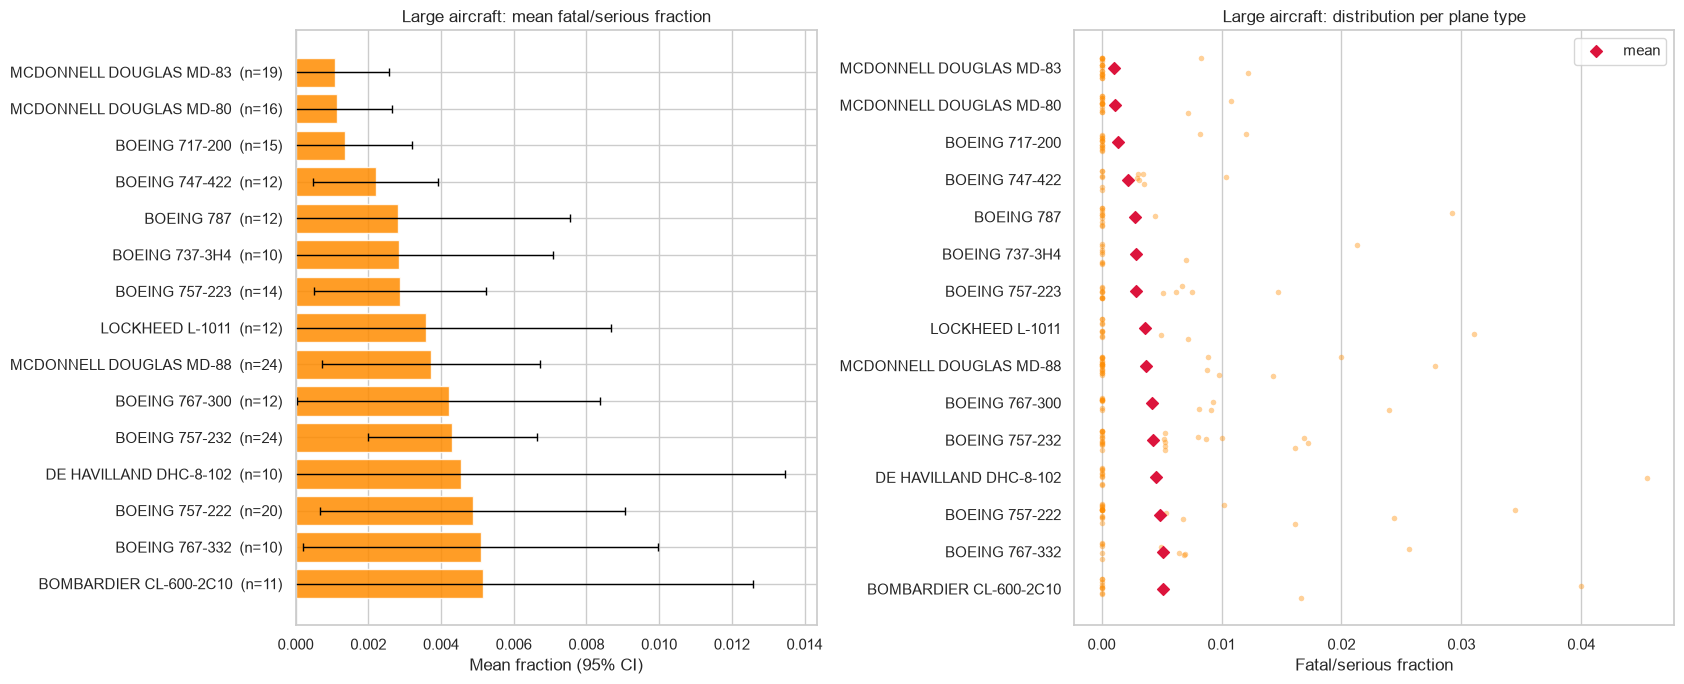

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(17, 7), gridspec_kw={"width_ratios": [1, 1.15]})

# bar: mean fraction + CI
t = top_models_large
hbar(axes[0], t, "mean_fs", t["ci_fs"], "darkorange", xlabel="Mean fraction (95% CI)")
axes[0].set_title("Large aircraft: mean fatal/serious fraction")

# strip: the distribution behind each mean
sns.stripplot(data=large[large["Make.Model"].isin(t.index)], y="Make.Model", x="Fatal.Serious.Fraction",
              order=t.index, orient="h", jitter=0.28, alpha=0.4, size=4, color="darkorange", ax=axes[1])
axes[1].scatter(t["mean_fs"], range(len(t)), color="crimson", zorder=5, marker="D", label="mean")
axes[1].set(title="Large aircraft: distribution per plane type", xlabel="Fatal/serious fraction", ylabel=""); axes[1].legend()
plt.tight_layout(); plt.show()

**Smaller planes**
- for smaller planes, limit your plotted results to the makes with the 10 lowest mean serious/fatal injury fractions

,n,mean_fs,ci_fs,any_fs,any_fs_hi,destroyed_rate
Make.Model,,,,,,
GRUMMAN G164B,16,0.000,0.000,0.000,0.194,0.062
CESSNA 180C,15,0.000,0.000,0.000,0.204,0.067
PIPER PA-18A 150,12,0.000,0.000,0.000,0.243,0.000
DIAMOND DA 20 C1,11,0.000,0.000,0.000,0.259,0.000
MCDONNELL DOUGLAS MD-11F,11,0.000,0.000,0.000,0.259,0.100
MAULE MX-7-235,17,0.029,0.058,0.059,0.270,0.000
CESSNA 560XL,25,0.040,0.078,0.040,0.195,0.125
CESSNA C172,12,0.042,0.082,0.083,0.354,0.000
NORTH AMERICAN AT-6G,11,0.045,0.089,0.091,0.377,0.000


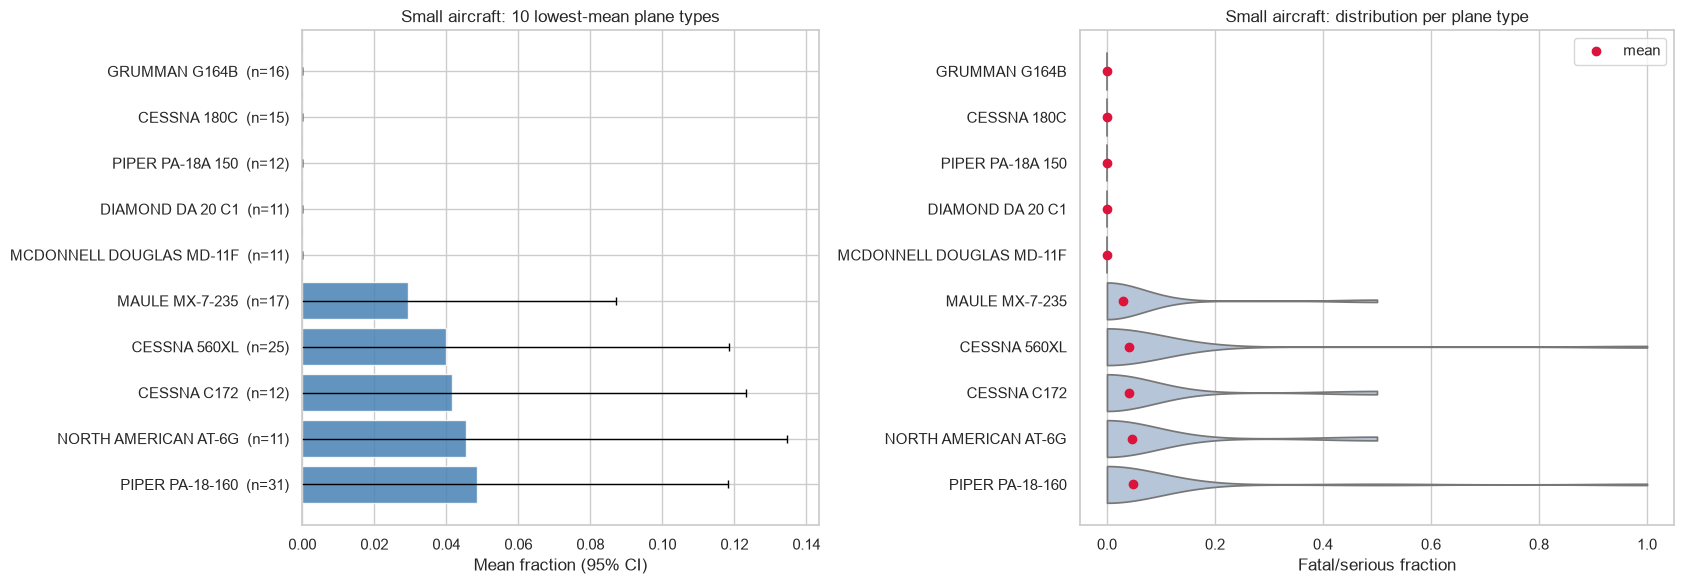

In [17]:
top_models_small = model_small.sort_values(["mean_fs", "n"], ascending=[True, False]).head(10)
display(top_models_small[["n", "mean_fs", "ci_fs", "any_fs", "any_fs_hi", "destroyed_rate"]].round(3))

fig, axes = plt.subplots(1, 2, figsize=(17, 6), gridspec_kw={"width_ratios": [1, 1.15]})
t = top_models_small
hbar(axes[0], t, "mean_fs", t["ci_fs"], "steelblue", xlabel="Mean fraction (95% CI)")
axes[0].set_title("Small aircraft: 10 lowest-mean plane types")

sns.violinplot(data=small[small["Make.Model"].isin(t.index)], y="Make.Model", x="Fatal.Serious.Fraction",
               order=t.index, orient="h", cut=0, inner=None, density_norm="width", color="lightsteelblue", ax=axes[1])
axes[1].scatter(t["mean_fs"], range(len(t)), color="crimson", zorder=5, label="mean")
axes[1].set(title="Small aircraft: distribution per plane type", xlabel="Fatal/serious fraction", ylabel=""); axes[1].legend()
plt.tight_layout(); plt.show()

### Discussion of Specific Airplane Types
- Discuss what you have found above regarding passenger fraction seriously/ both small and large airplane models.

In [18]:
# Robustness check: do the recommended plane types really differ from the rest of their size group?
from scipy import stats

for name, grp, top in [("Large", large, top_models_large), ("Small", small, top_models_small)]:
    pool = grp[grp["Make.Model"].isin(model_large.index if name == "Large" else model_small.index)]
    best = pool[pool["Make.Model"].isin(top.index)]["Fatal.Serious.Fraction"]
    rest = pool[~pool["Make.Model"].isin(top.index)]["Fatal.Serious.Fraction"]
    u, p = stats.mannwhitneyu(best, rest, alternative="less")
    print(f"{name}: recommended types mean = {best.mean():.3f} (n={len(best)})  vs  other types mean = {rest.mean():.3f} (n={len(rest)})   "
          f"Mann-Whitney one-sided p = {p:.2g}")

# Selection caveat: these types were picked *because* they had the lowest means, so the test above is optimistic
# ("winner's curse" / regression to the mean). A fairer check, repeated 200 times with random splits:
# choose the best types using half of each group's events, then measure them on the OTHER half.
rng = np.random.default_rng(0)
for name, grp, pool_idx, k in [("Large", large, model_large.index, 15), ("Small", small, model_small.index, 10)]:
    g = grp.loc[grp["Make.Model"].isin(pool_idx), ["Make.Model", "Fatal.Serious.Fraction"]].reset_index(drop=True)
    picked, rest = [], []
    for _ in range(200):
        half = rng.integers(0, 2, len(g)).astype(bool)
        chosen = g[~half].groupby("Make.Model")["Fatal.Serious.Fraction"].mean().nsmallest(k).index
        test = g[half]; hit = test["Make.Model"].isin(chosen)
        picked.append(test.loc[hit, "Fatal.Serious.Fraction"].mean()); rest.append(test.loc[~hit, "Fatal.Serious.Fraction"].mean())
    print(f"{name} hold-out (200 splits): top-{k} types chosen on half A score {np.nanmean(picked):.3f} on half B, "
          f"vs {np.nanmean(rest):.3f} for all other types")


Large: recommended types mean = 0.003 (n=221)  vs  other types mean = 0.088 (n=1218)   Mann-Whitney one-sided p = 0.17
Small: recommended types mean = 0.025 (n=161)  vs  other types mean = 0.273 (n=51347)   Mann-Whitney one-sided p = 5.8e-14
Large hold-out (200 splits): top-15 types chosen on half A score 0.048 on half B, vs 0.081 for all other types
Small hold-out (200 splits): top-10 types chosen on half A score 0.238 on half B, vs 0.272 for all other types


### Discussion - Specific plane types

**Large aircraft.** The plane types with the lowest mean fractions (at least 10 events each) are the **McDonnell Douglas MD-80 series (MD-80, MD-83, MD-88), Boeing 717-200, 747-422, 787, 757 (-222/-223/-232), 767 (-300/-332), 737-3H4, Lockheed L-1011 and Bombardier CL-600-2C10**; the strip plot shows that nearly every event for these types has a fraction of exactly 0 or a few percent.

But the statistical checks above urge caution:
- Each type has only 10-24 events, and the share of events with at least one serious/fatal injury has an upper 95% bound of **31%-76%** (`any_fs_hi`). The *individual* rankings of these types are therefore **not statistically distinguishable** from each other.
- In-sample, the 15 selected types do not differ significantly from the other large types (one-sided Mann-Whitney p = 0.17). In the repeated hold-out test (select on half the data, evaluate on the other half), the selected types score **0.048 vs 0.081** for the rest - a lower figure, but a much smaller gap than the in-sample 0.003 vs 0.088, which shows how much of the apparent edge is selection luck.
- **Conclusion:** recommend at the *family* level (MD-80 series, Boeing 717/757/767/787, Bombardier CL-600) rather than treating, say, an MD-83 as meaningfully safer than a 757-223. Types that have few events (new designs such as the 787 and A350 have little history) should be re-evaluated as data accumulate.

**Small aircraft.** Among 720 plane types with at least 10 events, five have a mean of exactly 0.000 (**Grumman G-164B, Cessna 180C, Piper PA-18A-150, Diamond DA-20-C1** and a McDonnell Douglas MD-11F freighter, which is "small" only because a freighter carries 3 crew), followed by Maule MX-7-235, **Cessna 560XL, Cessna 172 (C172 label), North American AT-6G and Piper PA-18-160**.
- Zero-width error bars for the all-zero types are misleading: with 11-16 injury-free events, the true share of events with a serious injury could still be **19%-26%** (`any_fs_hi`).
- The violin plot also shows the other side: even for these types a few events reach a fraction of 1.
- The hold-out test is sobering: the 10 "best" small types score **0.238** on fresh data against **0.272** for the others, so most of the in-sample advantage (0.025 vs 0.273) was regression to the mean. A real but modest edge remains.
- **Practical shortlist** (types with the most events and a still-low mean): **Piper PA-18-160 (Super Cub, n = 31), Cessna 560XL (n = 25), Maule MX-7-235 (n = 17), Cessna 180C (n = 15), Grumman G-164B (n = 16)**. Backing this with the make-level results, Cessna, Maule, Aviat and Diamond are the better-supported choices.

**Overall:** the make-level conclusions are statistically sturdier than the type-level ones, because the latter rest on samples of 10-30 events in a heavily zero-inflated distribution.


### Exploring Other Variables
- Investigate how other variables effect aircraft damage and injury. You must choose **two** factors out of the following but are free to analyze more:

- Weather Condition
- Engine Type
- Number of Engines
- Phase of Flight
- Purpose of Flight

For each factor provide a discussion explaining your analysis with appropriate visualization / data summaries and interpreting your findings.

We analyse **three** factors: **Weather Condition**, **Number of Engines** and **Phase of Flight** (the task requires at least two). For each one we look at the two outcome measures - fatal/serious fraction and destroyed rate - and test whether the differences are statistically significant. Because small and large aircraft are such different populations, results are shown separately where the sample allows.

A small helper is defined first.

In [19]:
from scipy import stats

def factor_table(data, col, min_n=30):
    t = summarize(data, col)
    return t[t["n"] >= min_n]

def plot_factor(tbl, title, order=None, rot=0):
    """Two side-by-side bar charts: injury fraction (normal CI) and destroyed rate (Wilson CI)."""
    tbl = tbl.loc[order] if order is not None else tbl
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
    x = np.arange(len(tbl))
    axes[0].bar(x, tbl["mean_fs"], yerr=tbl["ci_fs"], color="indianred", alpha=0.85, capsize=4)
    axes[0].set(title=f"{title}\nmean fatal/serious fraction", ylabel="Mean fraction (95% CI)")
    err = np.vstack([tbl["destroyed_rate"] - tbl["destroyed_lo"], tbl["destroyed_hi"] - tbl["destroyed_rate"]])
    axes[1].bar(x, tbl["destroyed_rate"], yerr=err, color="slategray", alpha=0.85, capsize=4)
    axes[1].set(title=f"{title}\naircraft destroyed rate", ylabel="Destroyed rate (95% Wilson CI)")
    for ax in axes:
        ax.set_xticks(x); ax.set_xticklabels([f"{i}\n(n={int(n):,})" for i, n in zip(tbl.index, tbl["n"])], rotation=rot)
        ax.set_xlabel("")
    plt.tight_layout(); plt.show()

def compare_two(data, col, a, b):
    """Significance tests for two groups: Mann-Whitney (injury fraction) and chi-square (destroyed)."""
    A, B = data[data[col] == a], data[data[col] == b]
    u, p_fs = stats.mannwhitneyu(A["Fatal.Serious.Fraction"], B["Fatal.Serious.Fraction"])
    ct = pd.crosstab(data.loc[data[col].isin([a, b]), col], data.loc[data[col].isin([a, b]), "Destroyed"])
    chi2, p_d, _, _ = stats.chi2_contingency(ct)
    print(f"{a} vs {b}:  injury fraction {A['Fatal.Serious.Fraction'].mean():.3f} vs {B['Fatal.Serious.Fraction'].mean():.3f} "
          f"(Mann-Whitney p = {p_fs:.2g});  destroyed {A['Destroyed'].mean():.3f} vs {B['Destroyed'].mean():.3f} (chi-square p = {p_d:.2g})")

### Factor 1 - Weather Condition (VMC = visual conditions, IMC = instrument conditions)

All aircraft


,n,mean_fs,ci_fs,destroyed_rate,destroyed_lo,destroyed_hi
Weather.Condition,,,,,,
IMC,4496,0.659,0.013,0.587,0.573,0.602
VMC,50025,0.219,0.003,0.163,0.160,0.166


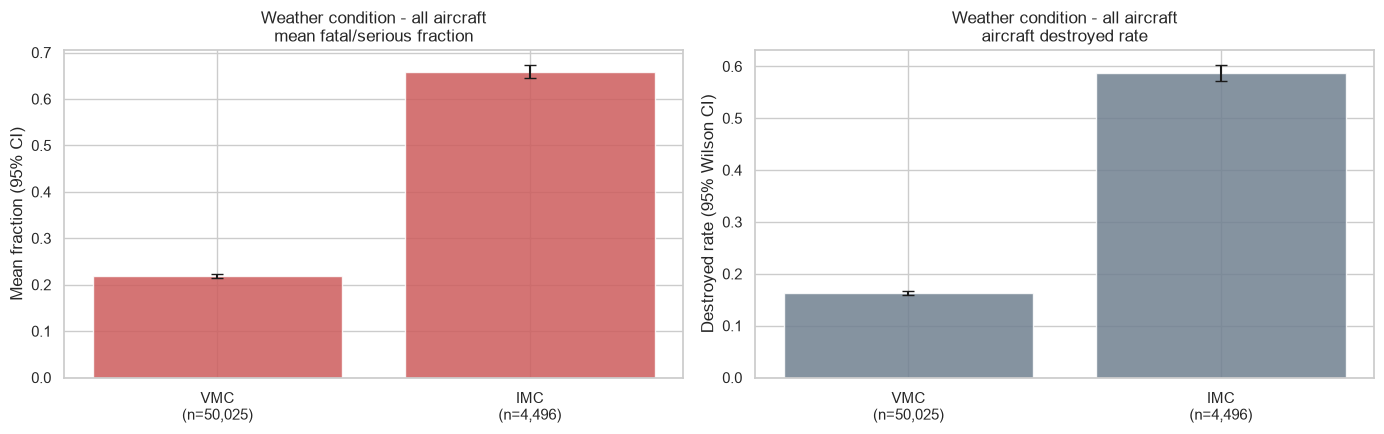

VMC vs IMC:  injury fraction 0.219 vs 0.659 (Mann-Whitney p = 0);  destroyed 0.163 vs 0.587 (chi-square p = 0)

VMC vs IMC:  injury fraction 0.223 vs 0.689 (Mann-Whitney p = 0);  destroyed 0.164 vs 0.599 (chi-square p = 0)
   (n: VMC = 48,853, IMC = 4,242)

VMC vs IMC:  injury fraction 0.041 vs 0.152 (Mann-Whitney p = 1.1e-11);  destroyed 0.060 vs 0.256 (chi-square p = 1.6e-13)
   (n: VMC = 1,172, IMC = 254)


In [20]:
known_wx = df[df["Weather.Condition"].isin(["VMC", "IMC"])]       # "Unknown" is excluded from the comparison
print("All aircraft")
wx_all = factor_table(known_wx, "Weather.Condition"); display(wx_all.round(3)[["n", "mean_fs", "ci_fs", "destroyed_rate", "destroyed_lo", "destroyed_hi"]])
plot_factor(wx_all, "Weather condition - all aircraft", order=["VMC", "IMC"])
compare_two(known_wx, "Weather.Condition", "VMC", "IMC")

for size_name in ["Small", "Large"]:
    print()
    compare_two(known_wx[known_wx["Size.Class"] == size_name], "Weather.Condition", "VMC", "IMC")
    d = known_wx[known_wx["Size.Class"] == size_name]
    print(f"   (n: VMC = {(d['Weather.Condition']=='VMC').sum():,}, IMC = {(d['Weather.Condition']=='IMC').sum():,})")

In [21]:
# Is the weather effect just a flight-phase effect? Break fatal/serious fraction down by weather within the main phases (small aircraft).
sm = known_wx[(known_wx["Size.Class"] == "Small") & known_wx["Broad.phase.of.flight"].isin(["Takeoff", "Cruise", "Approach", "Landing", "Maneuvering"])]
pivot = sm.pivot_table(index="Broad.phase.of.flight", columns="Weather.Condition", values="Fatal.Serious.Fraction", aggfunc=["mean", "size"])
pivot.round(3)

mean         size       
Weather.Condition        IMC    VMC   IMC    VMC
Broad.phase.of.flight                           
Approach               0.708  0.269   751   3366
Cruise                 0.757  0.244  1193   5244
Landing                0.086  0.033   241  10746
Maneuvering            0.819  0.498   319   3900
Takeoff                0.583  0.212   314   7780

### Findings - Weather Condition

- **Instrument conditions are dramatically more dangerous once an event occurs.** Across all aircraft the mean fatal/serious fraction is **0.659 in IMC vs 0.219 in VMC**, and the destroyed rate is **58.7% vs 16.3%** (n = 4,496 IMC vs 50,025 VMC events; both tests p < 1e-100).
- The pattern holds in **both size classes**: small aircraft 0.689 vs 0.223 (destroyed 59.9% vs 16.4%); large aircraft 0.152 vs 0.041 (destroyed 25.6% vs 6.0%, n = 254 IMC events, p ~ 1e-11 / 1e-13). Weather matters for large aircraft too, though the absolute levels are far lower.
- It is **not just a flight-phase effect**: for small aircraft the IMC penalty appears in every main phase - approach 0.708 vs 0.269, cruise 0.757 vs 0.244, maneuvering 0.819 vs 0.498, takeoff 0.583 vs 0.212, and even landing (0.086 vs 0.033).
- *Interpretation and limits:* this compares severity **given that an event happened**; we have no flight-hours, so we cannot say how often IMC flights have events. Events with unknown weather (~2,900) are excluded. Plausible mechanisms are loss of control / spatial disorientation and controlled flight into terrain when visibility is poor, which tend to be high-energy impacts.
- *Implication for the client:* conditions of operation (instrument-weather exposure, pilot instrument proficiency) are a much bigger severity driver than most differences between makes. Underwriting should weight operations in IMC heavily.


### Factor 2 - Number of Engines

In [22]:
eng = df[df["Number.of.Engines"].notna()].copy()
eng["Engines"] = eng["Number.of.Engines"].astype(int).clip(upper=3).map({1: "1", 2: "2", 3: "3+"})   # 3 and 4 engines pooled: few samples

print("Event counts by size class and engine count:")
display(pd.crosstab(eng["Size.Class"], eng["Engines"]))

eng_small = factor_table(eng[eng["Size.Class"] == "Small"], "Engines", min_n=30)
eng_large = factor_table(eng[eng["Size.Class"] == "Large"], "Engines", min_n=30)
print("Small aircraft"); display(eng_small[["n", "mean_fs", "ci_fs", "destroyed_rate", "destroyed_lo", "destroyed_hi"]].round(3))
print("Large aircraft"); display(eng_large[["n", "mean_fs", "ci_fs", "destroyed_rate", "destroyed_lo", "destroyed_hi"]].round(3))

Event counts by size class and engine count:


Engines,1,2,3+
Size.Class,,,
Large,3,1705,424
Small,48032,7023,83


Small aircraft


C:\Users\ADMIN\AppData\Local\Temp\ipykernel_11208\3737016603.py:5: RuntimeWarning: divide by zero encountered in divide
  denom = 1 + z**2 / n
C:\Users\ADMIN\AppData\Local\Temp\ipykernel_11208\3737016603.py:6: RuntimeWarning: divide by zero encountered in divide
  centre = (p + z**2 / (2 * n)) / denom
C:\Users\ADMIN\AppData\Local\Temp\ipykernel_11208\3737016603.py:6: RuntimeWarning: invalid value encountered in divide
  centre = (p + z**2 / (2 * n)) / denom
C:\Users\ADMIN\AppData\Local\Temp\ipykernel_11208\3737016603.py:7: RuntimeWarning: invalid value encountered in divide
  half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
C:\Users\ADMIN\AppData\Local\Temp\ipykernel_11208\3737016603.py:7: RuntimeWarning: divide by zero encountered in divide
  half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom


,n,mean_fs,ci_fs,destroyed_rate,destroyed_lo,destroyed_hi
Engines,,,,,,
1,48032,0.260,0.004,0.190,0.186,0.193
2,7023,0.367,0.011,0.327,0.316,0.339
3+,83,0.254,0.090,0.274,0.185,0.386


Large aircraft


,n,mean_fs,ci_fs,destroyed_rate,destroyed_lo,destroyed_hi
Engines,,,,,,
2,1705,0.074,0.012,0.127,0.107,0.150
3+,424,0.058,0.020,0.095,0.065,0.135


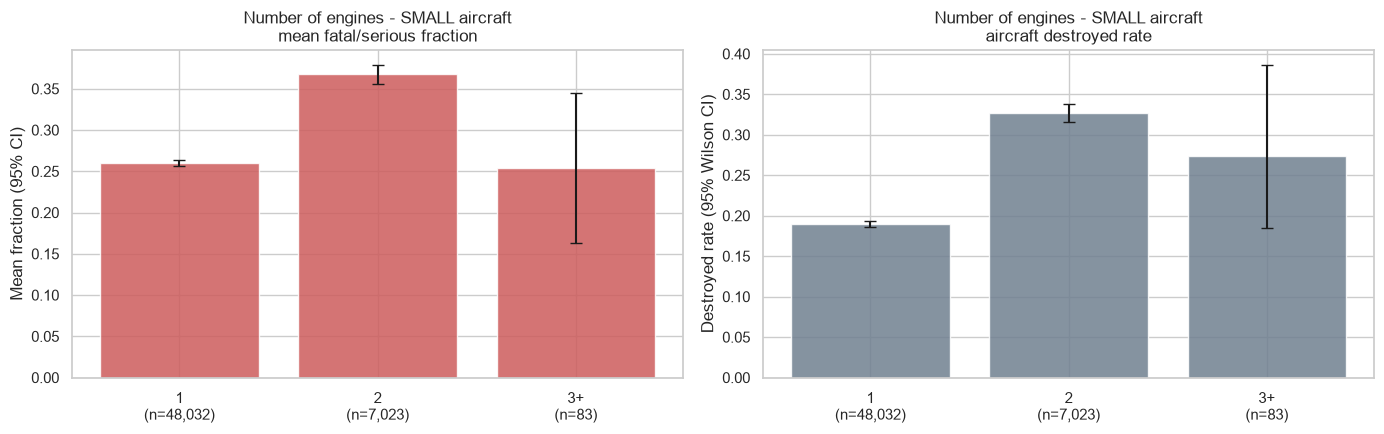

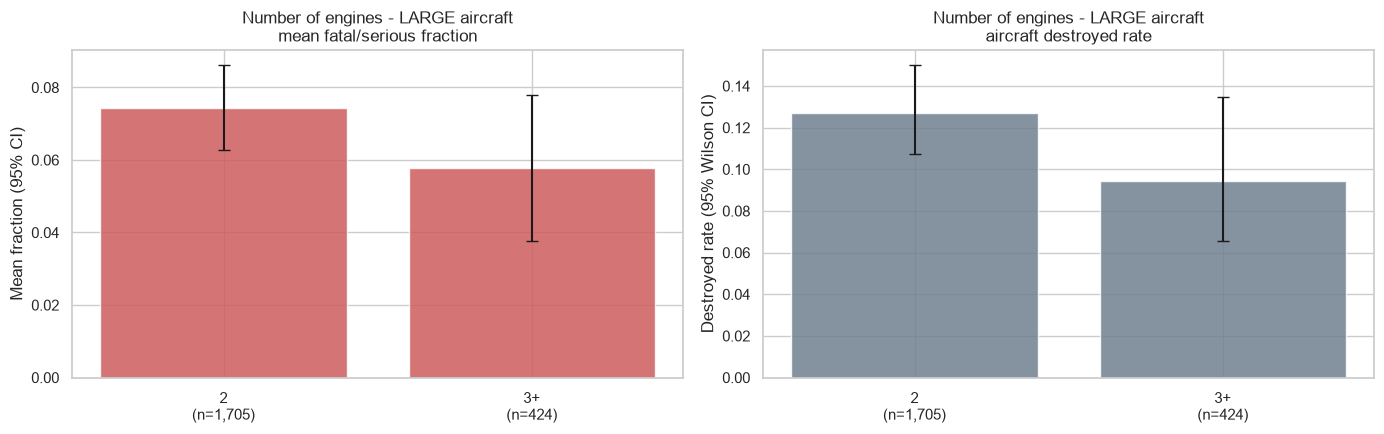

1 vs 2:  injury fraction 0.260 vs 0.367 (Mann-Whitney p = 5.1e-87);  destroyed 0.190 vs 0.327 (chi-square p = 2.5e-151)
2 vs 3+:  injury fraction 0.074 vs 0.058 (Mann-Whitney p = 0.22);  destroyed 0.127 vs 0.095 (chi-square p = 0.18)


In [23]:
plot_factor(eng_small, "Number of engines - SMALL aircraft")
plot_factor(eng_large, "Number of engines - LARGE aircraft")

compare_two(eng[eng["Size.Class"] == "Small"], "Engines", "1", "2")
compare_two(eng[eng["Size.Class"] == "Large"], "Engines", "2", "3+")

Twin-engine small aircraft look *worse* than single-engine ones, which is counter-intuitive. Before interpreting this we check whether the two groups are even comparable (same missions, same weather) and whether the gap survives stratification.

In [24]:
sm_eng = eng[(eng["Size.Class"] == "Small") & eng["Engines"].isin(["1", "2"])]

profile = sm_eng.groupby("Engines").agg(
    events=("Engines", "size"),
    mean_occupants=("Total.Passengers", "mean"),
    share_IMC=("Weather.Condition", lambda s: (s == "IMC").mean()),
    share_business=("Purpose.of.flight", lambda s: (s == "Business").mean()),
    share_instructional=("Purpose.of.flight", lambda s: (s == "Instructional").mean()))
print("Who flies single- vs twin-engine small aircraft?"); display(profile.round(3))

strat = (sm_eng[sm_eng["Weather.Condition"].isin(["VMC", "IMC"])]
         .pivot_table(index="Weather.Condition", columns="Engines", values=["Fatal.Serious.Fraction", "Destroyed"], aggfunc="mean"))
print("Outcome by engine count, within each weather condition:"); display(strat.round(3))

Who flies single- vs twin-engine small aircraft?


,events,mean_occupants,share_IMC,share_business,share_instructional
Engines,,,,,
1,48032,1.890,0.061,0.042,0.153
2,7023,3.309,0.182,0.142,0.082


Outcome by engine count, within each weather condition:


Destroyed        Fatal.Serious.Fraction       
Engines                   1      2                      1      2
Weather.Condition                                               
IMC                   0.615  0.562                  0.725  0.607
VMC                   0.153  0.258                  0.215  0.290

### Findings - Number of Engines

- **Large aircraft are almost all multi-engine** (1,705 twins, 424 with 3+; only 3 single-engine), so engine count is mostly confounded with size and **no meaningful single- vs multi-engine comparison is possible there**. Twins vs 3+ engines: 0.074 vs 0.058 injury fraction and 12.7% vs 9.5% destroyed - **not statistically significant** (p = 0.22, 0.18). More engines on a big jet is not shown to be safer in this data.
- **Small aircraft: twin-engine aircraft do worse, not better** - 0.367 vs 0.260 injury fraction and 32.7% vs 19.0% destroyed (n = 7,023 vs 48,032; p < 1e-80). The 3+ group (n = 83) is too small to conclude anything.
- This should **not** be read as "an extra engine makes a plane more dangerous." The two groups are different populations: twins fly in IMC **18.2%** of events vs **6.1%** for singles, are used for business flying 14.2% vs 4.2% (vs instructional 8.2% vs 15.3%), and carry more occupants (3.3 vs 1.9).
- Stratifying by weather is revealing: in **VMC** twins still do worse (0.290 vs 0.215; destroyed 25.8% vs 15.3%), but in **IMC** twins do *better* (0.607 vs 0.725; destroyed 56.2% vs 61.5%), consistent with engine redundancy helping when conditions are hard, and with higher-performance twins being flown faster and at higher energy in visual conditions.
- *Implication:* engine count is a weak, confounded indicator. For small aircraft, the data does not support "twin = safer", and the client should not price on engine count alone. Better controls (pilot experience, aircraft speed, mission) are not in this dataset.


### Factor 3 (bonus) - Phase of Flight

Small aircraft


,n,mean_fs,ci_fs,destroyed_rate
Broad.phase.of.flight,,,,
Taxi,1231,0.021,0.007,0.022
Landing,11022,0.035,0.003,0.042
Standing,486,0.165,0.026,0.135
Takeoff,8120,0.226,0.009,0.216
Go-around,1097,0.297,0.026,0.283
Descent,1153,0.346,0.027,0.332
Cruise,6592,0.351,0.011,0.341
Approach,4141,0.351,0.014,0.299
Climb,1257,0.434,0.026,0.438


Large aircraft


,n,mean_fs,ci_fs,destroyed_rate
Broad.phase.of.flight,,,,
Taxi,154,0.003,0.003,0.000
Standing,70,0.016,0.009,0.000
Descent,88,0.019,0.022,0.000
Landing,127,0.031,0.027,0.078
Climb,82,0.037,0.038,0.073
Takeoff,138,0.038,0.031,0.062
Cruise,155,0.059,0.033,0.167
Approach,95,0.109,0.061,0.145


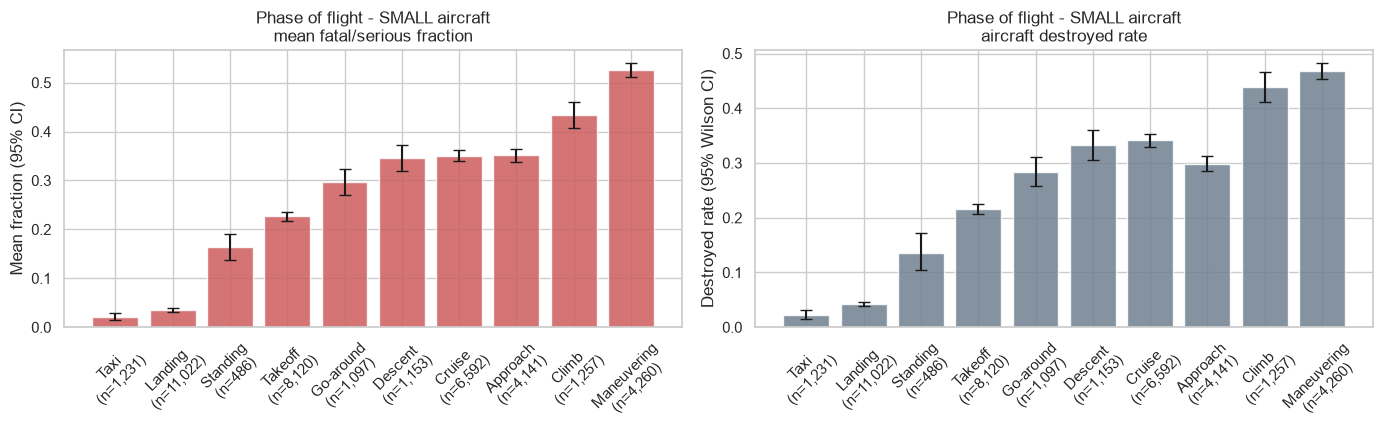

Kruskal-Wallis across phases (small aircraft): H = 6133, p = 0


In [25]:
phase = df[~df["Broad.phase.of.flight"].isin(["Unknown", "Other"])]
ph_small = factor_table(phase[phase["Size.Class"] == "Small"], "Broad.phase.of.flight", min_n=100).sort_values("mean_fs")
ph_large = factor_table(phase[phase["Size.Class"] == "Large"], "Broad.phase.of.flight", min_n=30).sort_values("mean_fs")

print("Small aircraft"); display(ph_small[["n", "mean_fs", "ci_fs", "destroyed_rate"]].round(3))
print("Large aircraft"); display(ph_large[["n", "mean_fs", "ci_fs", "destroyed_rate"]].round(3))
plot_factor(ph_small, "Phase of flight - SMALL aircraft", rot=45)

h, p = stats.kruskal(*[g["Fatal.Serious.Fraction"].values for _, g in phase[phase["Size.Class"] == "Small"].groupby("Broad.phase.of.flight") if len(g) >= 100])
print(f"Kruskal-Wallis across phases (small aircraft): H = {h:.0f}, p = {p:.2g}")

### Findings - Phase of Flight (bonus factor)

- For **small aircraft** (differences highly significant, Kruskal-Wallis p ~ 0) the severity is lowest during **taxi (0.021) and landing (0.035)** - the most *frequent* phase (11,022 events) but low-speed - and highest during **maneuvering (0.525, destroyed 46.8%) and climb (0.434, destroyed 43.8%)**, followed by cruise/approach/descent (~0.35). Low-altitude maneuvering leaves no room to recover, and climb-out stalls and engine failures are high-energy.
- For **large aircraft** the samples per phase are small (70-155 events), intervals are wide, and all phases have fractions under about 0.11; only the tendency for approach (0.109) and cruise (0.059) to be worse than taxi/standing/descent/landing is visible, and it is **not statistically robust**.
- *Implication:* operations dominated by low-level maneuvering (aerial application, aerobatics, banner towing) carry a higher severity once something goes wrong - one reason why the vintage/ag aircraft that look good on injury fraction should be interpreted cautiously.


## Summary of recommendations for the client

**Small aircraft (< 20 occupants):** best-supported choices are **Cessna** (best evidence base; better than average on both measures), **Maule, Aviat and Diamond** (lowest destroyed rates with adequate samples). Higher-performance **Beech, Mooney and Cirrus** have above-average severity and warrant higher premiums or closer review of how they are operated. Vintage/ag types (Waco, Great Lakes, Stearman, Ag-Cat) show low injury fractions but represent niche usage and small samples.

**Large aircraft (20+ occupants):** **Bombardier, Embraer, McDonnell Douglas, Boeing and Airbus** are the lowest-risk makes on both measures; recommend at the family level (MD-80 series, Boeing 717/757/767/787, Bombardier CL-600) because individual-type samples are too small to separate. **De Havilland, Douglas and Beech** (older commuter/early jet types) are worse.

**Contributing factors (all with supporting tables, plots and tests above):**
1. **Weather condition** - IMC events have ~3x the serious/fatal fraction and ~3.6x the destroyed rate of VMC events (small and large aircraft).
2. **Phase of flight** - maneuvering and climb are the most severe phases for small aircraft; landing and taxi the least.
3. **Number of engines** - not a protective factor on its own: twins do worse overall, mainly because of how they are used (more IMC, more business flying); they do better than singles only in IMC.

**Limitations.** (1) The data contains **events, not flights**: with no exposure (flight hours) we measure severity *given an event*, not the probability of having one. (2) The data is over 90% US events (NTSB). (3) `Total.Passengers` counts all occupants including crew. (4) Size class is estimated from each type's occupant distribution (90th percentile >= 20). (5) Model variants (172M, 172N ...) are treated as separate types, which reduces samples. (6) Associations are observational; weather, mission and aircraft type are intertwined.
